Dataset: IMDB movie reviews



Input: Tokenized review, padded to 200 tokens



Embedding dimension: 64



Attention heads: 4



Transformer blocks: 2



Output: Positive or negative sentiment

Import libraries and load the dataset

In [36]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Dataset configuration
vocab_size = 10000
maxlen = 200
embed_dim = 64
num_heads = 4
ff_dim = 128

# Load the IMDB dataset
(X_train, y_train), (X_test, y_test) = keras.datasets.imdb.load_data(
    num_words=vocab_size
)

# Pad or truncate reviews
X_train = pad_sequences(
    X_train, maxlen=maxlen, padding="post", truncating="post"
)

X_test = pad_sequences(
    X_test, maxlen=maxlen, padding="post", truncating="post"
)

# Create lowercase aliases for your existing training cell
x_train = X_train
x_test = X_test

print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing data:", x_test.shape)
print("Testing labels:", y_test.shape)

print("Dataset loaded successfully!")


Training data: (25000, 200)
Training labels: (25000,)
Testing data: (25000, 200)
Testing labels: (25000,)
Dataset loaded successfully!


Create the embedding and positional embedding layer

In [30]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim):
        super().__init__()
        self.supports_masking = True

        self.token_embedding = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            mask_zero=True
        )

        self.position_embedding = layers.Embedding(
            input_dim=maxlen,
            output_dim=embed_dim
        )

    def call(self, inputs):
        length = tf.shape(inputs)[-1]
        positions = tf.range(start=0, limit=length, delta=1)

        token_embeddings = self.token_embedding(inputs)
        position_embeddings = self.position_embedding(positions)

        return token_embeddings + position_embeddings

    def compute_mask(self, inputs, mask=None):
        return self.token_embedding.compute_mask(inputs)

Build the Transformer encoder block

In [31]:
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout_rate=0.1):
        super().__init__()
        self.supports_masking = True

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim)
        ])

        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, inputs, training=None, mask=None):
        attention_mask = None

        if mask is not None:
            attention_mask = tf.expand_dims(mask, axis=1)

        attention_output = self.attention(
            query=inputs,
            value=inputs,
            key=inputs,
            attention_mask=attention_mask,
            training=training
        )

        attention_output = self.dropout1(
            attention_output, training=training
        )
        out1 = self.norm1(inputs + attention_output)

        ffn_output = self.ffn(out1, training=training)
        ffn_output = self.dropout2(ffn_output, training=training)

        return self.norm2(out1 + ffn_output)
        return mask

Build, compile, and train the complete model

In [32]:
print("\nBuilding Transformer model...")

embed_dim = 64
num_heads = 4
ff_dim = 128

inputs = layers.Input(shape=(maxlen,), dtype="int32")

x = TokenAndPositionEmbedding(
    maxlen, vocab_size, embed_dim
)(inputs)

x = TransformerBlock(
    embed_dim, num_heads, ff_dim
)(x)

# Explicitly exclude padding tokens from average pooling
valid_tokens = layers.Lambda(
    lambda tokens: tf.cast(
        tf.not_equal(tokens, 0), tf.float32
    )
)(inputs)

x = layers.GlobalAveragePooling1D()(x, mask=keras.ops.not_equal(inputs, 0))
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inputs, outputs=outputs)


Building Transformer model...


In [33]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("\nModel compiled successfully!")

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 200)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, 200, 64)   │    652,800 │ input_layer_10[0… │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200)       │          0 │ input_layer_10[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block   │ (None, 200, 64)   │     33,472 │ token_and_positi… │
│ (TransformerBlock)  │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 200)       │          0 │ input_layer_10[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ transformer_bloc… │
│ (GlobalAveragePool… │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 64)        │      4,160 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_16[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_17 (Dense)    │ (None, 1)         │         65 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 690,497 (2.63 MB)

 Trainable params: 690,497 (2.63 MB)

 Non-trainable params: 0 (0.00 B)


Model compiled successfully!


In [37]:
print("\nTraining model...")

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    batch_size=64,
    epochs=5,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)


Training model...
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 151s 468ms/step - accuracy: 0.8009 - loss: 0.4186 - val_accuracy: 0.8696 - val_loss: 0.3091
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 152s 486ms/step - accuracy: 0.8986 - loss: 0.2548 - val_accuracy: 0.8674 - val_loss: 0.3097
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 151s 484ms/step - accuracy: 0.9212 - loss: 0.2016 - val_accuracy: 0.8666 - val_loss: 0.3286


In [38]:
print("\nEvaluating model on test data...")

test_loss, test_accuracy = model.evaluate(
    x_test, y_test, verbose=1
)

print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Evaluating model on test data...
782/782 ━━━━━━━━━━━━━━━━━━━━ 53s 67ms/step - accuracy: 0.8545 - loss: 0.3310

Test Loss: 0.3310
Test Accuracy: 85.45%


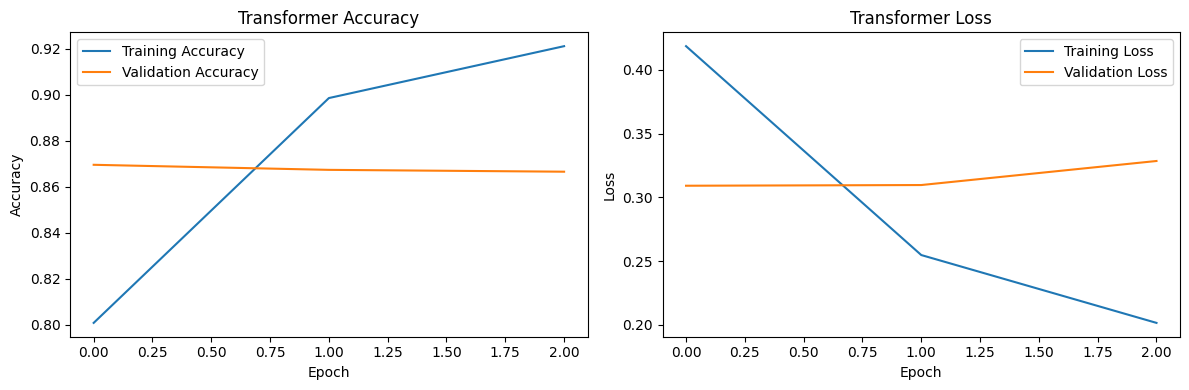

In [39]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Transformer Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [41]:
word_index = keras.datasets.imdb.get_word_index()

def predict_sentiment(review):
    # IMDB reserves IDs 0-3 for special tokens
    encoded = [
        1
    ] + [
        word_index.get(word.lower(), 2) + 3
        for word in review.split()
    ]

    # Unknown or out-of-vocabulary words map to UNK (ID 2)
    encoded = [
        token if 0 <= token < vocab_size else 2
        for token in encoded
    ]

    padded = keras.utils.pad_sequences(
        [encoded],
        maxlen=maxlen,
        padding="post",
        truncating="post"
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    print("\nReview:", review)
    print(f"Positive probability: {probability:.2%}")

    if probability >= 0.5:
        print("Predicted sentiment: POSITIVE 😊")
    else:
        print("Predicted sentiment: NEGATIVE 😞")

predict_sentiment(
    "This movie was excellent and I really enjoyed it"
)

predict_sentiment(
    "This movie was boring and terrible"
)

print("\nAll steps completed successfully!")


Review: This movie was excellent and I really enjoyed it
Positive probability: 99.85%
Predicted sentiment: POSITIVE 😊

Review: This movie was boring and terrible
Positive probability: 0.05%
Predicted sentiment: NEGATIVE 😞

All steps completed successfully!


In [42]:

# ==========================================
# TRANSFORMER SENTIMENT ANALYSIS GUI
# Using Gradio + TensorFlow/Keras
# ==========================================

import sys
import subprocess
import importlib.util
import re
import numpy as np
import tensorflow as tf
import keras

# Install Gradio if it is not already installed
if importlib.util.find_spec("gradio") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "gradio"
    ])

import gradio as gr

# Check that your trained model exists
if "model" not in globals():
    raise ValueError(
        "Model not found! Run your model-building and training cells first."
    )

# Use the same vocabulary settings as training
vocab_size = int(globals().get("vocab_size", 10000))
maxlen = int(globals().get("maxlen", 200))

# Load IMDB vocabulary
word_index = keras.datasets.imdb.get_word_index()


# ==========================================
# TEXT PREPROCESSING
# ==========================================
def preprocess_review(review):
    # Match the basic word normalization used by IMDB
    words = re.findall(r"\b[\w']+\b", review.lower())

    # IMDB reserves IDs 0-3 for special tokens
    sequence = [1]  # Start-of-review token

    for word in words:
        index = word_index.get(word)

        if index is None:
            token = 2  # Unknown word
        else:
            token = index + 3

        # Match the vocabulary cutoff used during training
        if token >= vocab_size:
            token = 2

        sequence.append(token)

    return keras.utils.pad_sequences(
        [sequence],
        maxlen=maxlen,
        padding="post",
        truncating="post"
    )


# ==========================================
# PREDICTION FUNCTION
# ==========================================
def analyze_sentiment(review):
    if not review or not review.strip():
        return (
            {"Positive": 0.0, "Negative": 0.0},
            "Please enter a movie review first."
        )

    review_input = preprocess_review(review)

    # Predict using the trained Transformer
    positive_probability = float(
        model.predict(review_input, verbose=0).reshape(-1)[0]
    )

    negative_probability = 1.0 - positive_probability

    scores = {
        "Positive": positive_probability,
        "Negative": negative_probability
    }

    confidence = max(
        positive_probability, negative_probability
    ) * 100

    if positive_probability >= 0.5:
        result = (
            "### 😊 Positive Sentiment\n"
            f"Predicted class: **POSITIVE**\n\n"
            f"Confidence score: **{confidence:.2f}%**"
        )
    else:
        result = (
            "### 😞 Negative Sentiment\n"
            f"Predicted class: **NEGATIVE**\n\n"
            f"Confidence score: **{confidence:.2f}%**"
        )

    return scores, result


# ==========================================
# BUILD GUI
# ==========================================
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # 🎬 Movie Review Sentiment Analyzer
        ### Powered by a Transformer Neural Network

        Enter a movie review below to predict its sentiment.
        """
    )

    review_input = gr.Textbox(
        label="Enter Your Movie Review",
        placeholder="Example: This movie was amazing, exciting, and enjoyable!",
        lines=5
    )

    with gr.Row():
        analyze_button = gr.Button(
            "🔍 Analyze Sentiment",
            variant="primary"
        )
        clear_button = gr.ClearButton(
            components=[review_input]
        )

    sentiment_output = gr.Label(
        label="Sentiment Scores",
        num_top_classes=2
    )

    result_output = gr.Markdown(
        "Your prediction will appear here."
    )

    analyze_button.click(
        fn=analyze_sentiment,
        inputs=review_input,
        outputs=[sentiment_output, result_output]
    )

    gr.Examples(
        examples=[
            ["This movie was fantastic. I loved the story and acting!"],
            ["This was a boring and terrible movie. I hated it."],
            ["The movie was okay, but the ending was disappointing."]
        ],
        inputs=review_input
    )

# Launch the browser interface
demo.launch()


/tmp/ipykernel_1660/384176447.py:115: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d18dc38a804360a1b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
